# Phase 02 - Correlation Analysis

## Objective

The objective of this analysis is to examine the relationship between Competence factors and Employability.

Correlation analysis is performed before regression and machine learning modelling to identify the strength and direction of relationships among research variables.

The analysis includes:

- Pearson correlation analysis
- Correlation matrix
- Heatmap visualization
- Statistical significance testing
- Spearman correlation validation

In [23]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from scipy.stats import spearmanr

## 2. Load Prepared Dataset

The processed Phase 02 dataset is loaded.

The dataset contains:

- Competence questionnaire items
- Employability questionnaire items
- Construct-level scores

The dataset prepared during preprocessing is used for correlation analysis.

In [24]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent


DATA_FILE = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
    /
    "phase2_competence_prepared.csv"
)


df = pd.read_csv(DATA_FILE)


print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


## 3. Define Research Variables

The research framework consists of:

Independent variable:
Competence

Dependent variable:
Employability

The variables are represented using validated questionnaire constructs.

In [25]:
competence_constructs = [
    "Comp_avg",
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]


employability_constructs = [
    "EVS_avg",
    "HumanCapital_avg",
    "SocialCapital_avg",
    "CareerIdentity_avg",
    "EnvironmentalMonitoring_avg",
    "Balance_avg"
]


correlation_variables = (
    competence_constructs
    +
    employability_constructs
)


df_corr = df[correlation_variables]


df_corr.head()

,Comp_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,EVS_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,3.3,3.50,3.000000,3.333333,4.750000,5.000000,4.0,4.75,5.0,5.0
1,3.7,3.50,4.000000,3.666667,3.500000,3.666667,3.5,3.75,4.0,2.5
2,3.4,3.25,3.333333,3.666667,3.750000,3.666667,4.0,3.75,4.0,3.5
3,3.9,4.00,4.000000,3.666667,4.000000,4.000000,4.0,4.00,4.0,4.0
4,4.3,4.00,4.666667,4.333333,4.333333,4.000000,4.5,4.50,5.0,4.0


## 4. Data Validation

Before calculating correlations, the dataset is checked for:

- Missing values
- Variable availability
- Data type consistency

In [26]:
print(
    "Missing values:"
)

df_corr.isnull().sum()

Missing values:


Comp_avg                       0
LifeCareer_avg                 0
LearningInnovation_avg         0
ITMedia_avg                    0
EVS_avg                        0
HumanCapital_avg               0
SocialCapital_avg              0
CareerIdentity_avg             0
EnvironmentalMonitoring_avg    0
Balance_avg                    0
dtype: int64

In [27]:
df_corr.dtypes

Comp_avg                       float64
LifeCareer_avg                 float64
LearningInnovation_avg         float64
ITMedia_avg                    float64
EVS_avg                        float64
HumanCapital_avg               float64
SocialCapital_avg              float64
CareerIdentity_avg             float64
EnvironmentalMonitoring_avg    float64
Balance_avg                    float64
dtype: object

## 5. Pearson Correlation Analysis

Pearson correlation coefficient is used to measure the linear relationship between Competence and Employability constructs.

The coefficient ranges from -1 to +1.

Positive values indicate that variables increase together, while negative values indicate an inverse relationship.

In [28]:
pearson_matrix = (
    df_corr
    .corr(method="pearson")
)


pearson_matrix

,Comp_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,EVS_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
Comp_avg,1.000000,0.915923,0.866740,0.876114,0.749306,0.723485,0.706853,0.505563,0.526075,0.594281
LifeCareer_avg,0.915923,1.000000,0.680174,0.681089,0.649466,0.638540,0.636241,0.428154,0.454161,0.503370
LearningInnovation_avg,0.866740,0.680174,1.000000,0.690881,0.668932,0.646129,0.639633,0.452541,0.474931,0.514954
ITMedia_avg,0.876114,0.681089,0.690881,1.000000,0.690201,0.650163,0.610253,0.478634,0.482286,0.578060
EVS_avg,0.749306,0.649466,0.668932,0.690201,1.000000,0.797423,0.739668,0.856594,0.704059,0.732860
HumanCapital_avg,0.723485,0.638540,0.646129,0.650163,0.797423,1.000000,0.680804,0.482422,0.556893,0.551528
SocialCapital_avg,0.706853,0.636241,0.639633,0.610253,0.739668,0.680804,1.000000,0.429881,0.503392,0.511813
CareerIdentity_avg,0.505563,0.428154,0.452541,0.478634,0.856594,0.482422,0.429881,1.000000,0.457538,0.457393
EnvironmentalMonitoring_avg,0.526075,0.454161,0.474931,0.482286,0.704059,0.556893,0.503392,0.457538,1.000000,0.673375
Balance_avg,0.594281,0.503370,0.514954,0.578060,0.732860,0.551528,0.511813,0.457393,0.673375,1.000000


## 6. Competence and Employability Relationship

The relationship between competence dimensions and overall employability is analysed.

This identifies which competence dimensions have stronger relationships with employability.

In [29]:
competence_evs_corr = (
    pearson_matrix
    .loc[
        competence_constructs,
        ["EVS_avg"]
    ]
)


competence_evs_corr

,EVS_avg
Comp_avg,0.749306
LifeCareer_avg,0.649466
LearningInnovation_avg,0.668932
ITMedia_avg,0.690201


## Correlation Strength Interpretation

The correlation coefficient values were interpreted based on their strength to understand the level of relationship between Competence factors and Employability.

The following guideline was used:

| Correlation Value | Interpretation |
|------------------|----------------|
| 0.00 - 0.19 | Very Weak |
| 0.20 - 0.39 | Weak |
| 0.40 - 0.59 | Moderate |
| 0.60 - 0.79 | Strong |
| 0.80 - 1.00 | Very Strong |


In [30]:
def correlation_strength(value):
    abs_value = abs(value)

    if abs_value < 0.20:
        return "Very Weak"
    
    elif abs_value < 0.40:
        return "Weak"
    
    elif abs_value < 0.60:
        return "Moderate"
    
    elif abs_value < 0.80:
        return "Strong"
    
    else:
        return "Very Strong"

In [31]:
correlation_interpretation = competence_evs_corr.copy()


correlation_interpretation.columns = [
    "Correlation"
]


correlation_interpretation["Strength"] = (
    correlation_interpretation["Correlation"]
    .apply(correlation_strength)
)


correlation_interpretation

,Correlation,Strength
Comp_avg,0.749306,Strong
LifeCareer_avg,0.649466,Strong
LearningInnovation_avg,0.668932,Strong
ITMedia_avg,0.690201,Strong


In [32]:
correlation_interpretation.to_csv(
    REPORT_DIR /
    "Correlation_Strength_Interpretation.csv"
)

## 7. Correlation Matrix

A complete correlation matrix is generated to examine relationships among all research constructs.

In [33]:
pearson_matrix

,Comp_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,EVS_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
Comp_avg,1.000000,0.915923,0.866740,0.876114,0.749306,0.723485,0.706853,0.505563,0.526075,0.594281
LifeCareer_avg,0.915923,1.000000,0.680174,0.681089,0.649466,0.638540,0.636241,0.428154,0.454161,0.503370
LearningInnovation_avg,0.866740,0.680174,1.000000,0.690881,0.668932,0.646129,0.639633,0.452541,0.474931,0.514954
ITMedia_avg,0.876114,0.681089,0.690881,1.000000,0.690201,0.650163,0.610253,0.478634,0.482286,0.578060
EVS_avg,0.749306,0.649466,0.668932,0.690201,1.000000,0.797423,0.739668,0.856594,0.704059,0.732860
HumanCapital_avg,0.723485,0.638540,0.646129,0.650163,0.797423,1.000000,0.680804,0.482422,0.556893,0.551528
SocialCapital_avg,0.706853,0.636241,0.639633,0.610253,0.739668,0.680804,1.000000,0.429881,0.503392,0.511813
CareerIdentity_avg,0.505563,0.428154,0.452541,0.478634,0.856594,0.482422,0.429881,1.000000,0.457538,0.457393
EnvironmentalMonitoring_avg,0.526075,0.454161,0.474931,0.482286,0.704059,0.556893,0.503392,0.457538,1.000000,0.673375
Balance_avg,0.594281,0.503370,0.514954,0.578060,0.732860,0.551528,0.511813,0.457393,0.673375,1.000000


## 8. Correlation Heatmap

The correlation matrix is visualized using a heatmap.

This provides an intuitive representation of relationships among Competence and Employability constructs.

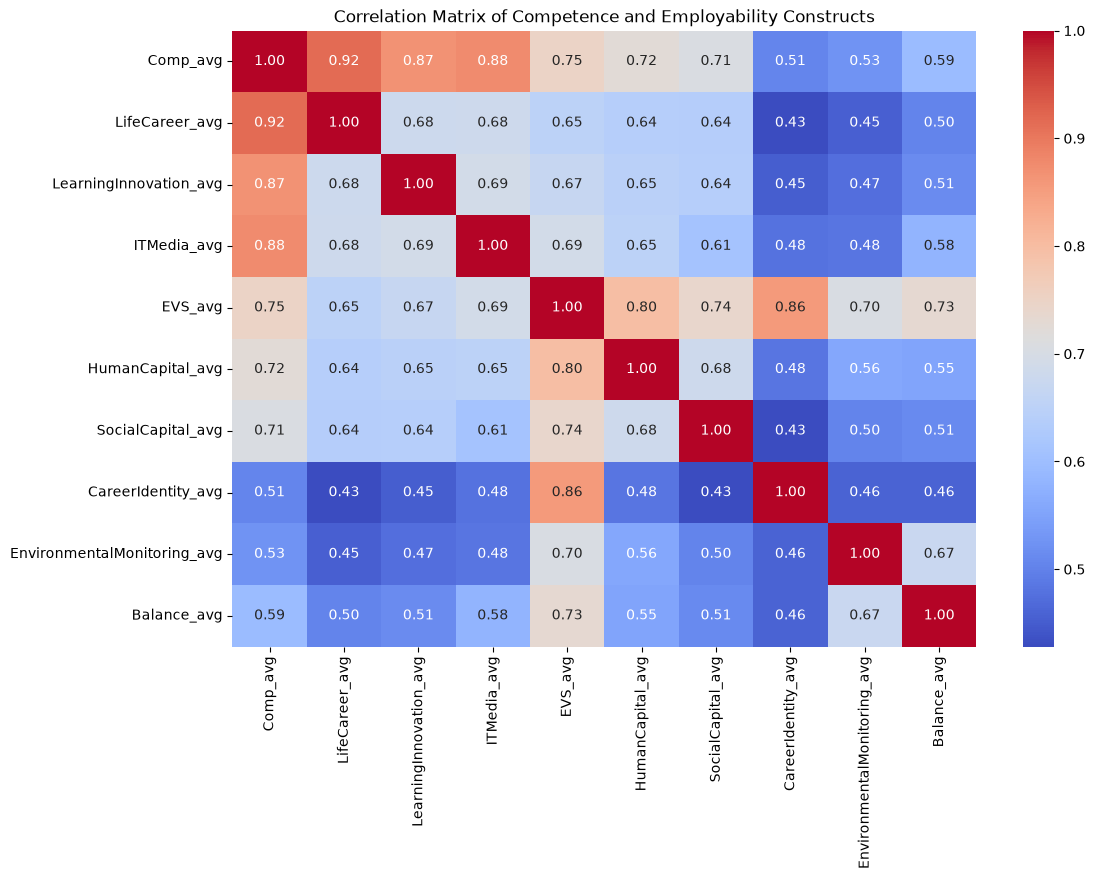

In [34]:
plt.figure(figsize=(12,8))


sns.heatmap(
    pearson_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)


plt.title(
    "Correlation Matrix of Competence and Employability Constructs"
)


plt.show()

## 9. Statistical Significance Testing

Pearson correlation significance tests are conducted to determine whether observed relationships are statistically meaningful.

In [35]:
results = []


for comp in competence_constructs:

    r, p = pearsonr(
        df[comp],
        df["EVS_avg"]
    )

    results.append(
        [
            comp,
            r,
            p
        ]
    )


correlation_significance = pd.DataFrame(
    results,
    columns=[
        "Variable",
        "Correlation",
        "P_Value"
    ]
)


correlation_significance

,Variable,Correlation,P_Value
0,Comp_avg,0.749306,7.762078e-181
1,LifeCareer_avg,0.649466,7.309369e-121
2,LearningInnovation_avg,0.668932,1.027878e-130
3,ITMedia_avg,0.690201,2.254259e-142


## 10. Spearman Correlation Validation

Spearman correlation is performed as an additional validation because questionnaire responses are measured using a Likert scale.

The results are compared with Pearson correlation findings.

In [36]:
spearman_results = []


for comp in competence_constructs:

    r, p = spearmanr(
        df[comp],
        df["EVS_avg"]
    )

    spearman_results.append(
        [
            comp,
            r,
            p
        ]
    )


spearman_results = pd.DataFrame(
    spearman_results,
    columns=[
        "Variable",
        "Spearman_Correlation",
        "P_Value"
    ]
)


spearman_results

,Variable,Spearman_Correlation,P_Value
0,Comp_avg,0.567138,3.503683e-86
1,LifeCareer_avg,0.471590,1.641617e-56
2,LearningInnovation_avg,0.503209,2.645261e-65
3,ITMedia_avg,0.548367,1.404358e-79


## Correlation Findings

The correlation analysis identified positive relationships between competence factors and employability.

Overall competence demonstrated a positive association with employability, indicating that students with stronger competence characteristics tend to report higher employability levels.

Among competence dimensions, the strongest relationships were observed in dimensions with higher correlation coefficients, suggesting their potential importance for employability prediction.

In [37]:
REPORT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "correlation"
)


REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [38]:
pearson_matrix.to_csv(
    REPORT_DIR /
    "Pearson_Correlation_Matrix.csv"
)


competence_evs_corr.to_csv(
    REPORT_DIR /
    "Competence_Employability_Correlation.csv"
)


correlation_significance.to_csv(
    REPORT_DIR /
    "Pearson_Correlation_PValues.csv",
    index=False
)


spearman_results.to_csv(
    REPORT_DIR /
    "Spearman_Correlation_Validation.csv",
    index=False
)

Competence vs Employability Scatter Plot

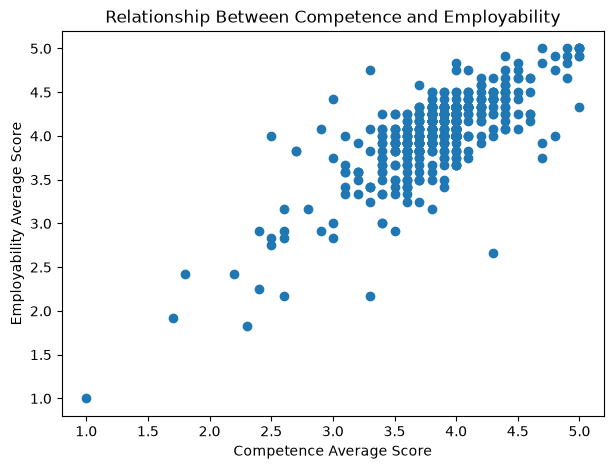

In [39]:
plt.figure(figsize=(7,5))

plt.scatter(
    df["Comp_avg"],
    df["EVS_avg"]
)

plt.xlabel("Competence Average Score")
plt.ylabel("Employability Average Score")

plt.title(
    "Relationship Between Competence and Employability"
)

plt.show()

## Hypothesis Evaluation

H1:
Competence is positively associated with employability.

Result:
Pearson correlation showed a strong positive relationship
(r = 0.749, p < 0.001).

Therefore, H1 is supported.

In [40]:
hypothesis_result = pd.DataFrame({
    "Hypothesis": [
        "H1: Competence has a significant positive relationship with Employability"
    ],
    "Correlation (r)": [
        df["Comp_avg"].corr(df["EVS_avg"])
    ],
    "P_Value": [
        pearsonr(
            df["Comp_avg"],
            df["EVS_avg"]
        )[1]
    ]
})


hypothesis_result

,Hypothesis,Correlation (r),P_Value
0,H1: Competence has a significant positive rela...,0.749306,7.762078e-181


In [41]:
hypothesis_result["Decision"] = np.where(
    hypothesis_result["P_Value"] < 0.05,
    "Supported",
    "Not Supported"
)


hypothesis_result

,Hypothesis,Correlation (r),P_Value,Decision
0,H1: Competence has a significant positive rela...,0.749306,7.762078e-181,Supported


In [42]:
hypothesis_result.to_csv(
    REPORT_DIR /
    "Hypothesis_Testing_Result.csv",
    index=False
)

In [43]:
import os

for file in os.listdir(REPORT_DIR):
    print(file)

Competence_Employability_Correlation.csv
Correlation_Strength_Interpretation.csv
Hypothesis_Testing_Result.csv
Pearson_Correlation_Matrix.csv
Pearson_Correlation_PValues.csv
Spearman_Correlation_Validation.csv
